# RQ2 - Can the original source of a text still be identified after translation?

**Question.** Each original T0 text was written either by a human (XSum) or by one of six LLM generators. A classifier
is trained to recognise this **source label** on original T0 texts. How well does it still recognise the source
after one, two or three English→Spanish→English round trips through each translator?

**Protocol (no leakage).**
- **Classes:** the seven actual source labels (Human, BigScience, Eleuther-AI, LLAMA, OpenAI, PaLM, Tsinghua).
  Chance level is 1/7.
- **Splitting:** folds are formed over **original article IDs** (31 articles, 5 folds, 5 shufflings). An article's
  texts (all 7 sources, every translator, every round) are always together on one side.
- **Training:** **original T0 texts of the training articles only**. The model never sees a translation.
- **Evaluation:** held-out articles' T0 texts, and each translator's T1/T2/T3 of the same held-out articles.
- **Models:** reproducible classical baselines with fixed (untuned) hyperparameters:
  - TF-IDF word 1-2-grams + logistic regression;
  - TF-IDF character 2-5-grams + logistic regression;
  - stylometric features + logistic regression (function words, punctuation, POS, dependency labels, sentence
    and word statistics);
  - a length-only control.
- **Primary cohort:** the matched cohort (documents complete for every translator), so every translator is scored on
  the same documents. All available texts are reported as a supplement.
- **Uncertainty:** the spread over the 5 shufflings (SD), and a 95% article-cluster bootstrap CI.

> **Public copy** by Samer Ahmed. This notebook was executed end to end from a clean kernel on 2026-11-01, and its saved outputs (tables, figures, interpretation) are shown as they were produced. The code cells call a shared research package and local, unpublished text tables (XSum texts and their translations) that are not part of this folder. They live in the development workspace (`Sam/` on branch `feature/sam-experiments`), so re-running needs that workspace. The aggregate result tables are in [`../results/`](../results/) and the figures in [`../figures/`](../figures/).

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src" / "sot_research").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sot_research import analysis, classify, corpus, features, paths, plots

%matplotlib inline
plots.setup()
pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 3)
CFG = corpus.research_config()
SEED, NB, NR = CFG["seed"], CFG["bootstrap_samples"], CFG["cv_repeats"]
print("python", sys.version.split()[0], "|", Path(sys.executable).parent.parent.name, "| pandas", pd.__version__)

D = analysis.load(require_text=True, pairs=False)
TR, NAMES, COL = D["translators"], D["names"], D["colors"]
OUT = paths.results("rq2")
F = D["features"]
STYLE = features.style_columns(F)
en = corpus.english(D["texts"]).merge(F[["text_id", "n_words", "n_sentences"] + STYLE], on="text_id", how="left")
en = classify.add_length_cols(en)
LABELS = [s for s in plots.SOURCE_ORDER if s in set(en.source_label)] + sorted(set(en.source_label) - set(plots.SOURCE_ORDER))
CHANCE = 1 / len(LABELS)
train_pool = en[en.stage == "T0"]
EVAL = {"original|T0": train_pool}
for t in TR:
    for k in (1, 2, 3):
        EVAL[f"{t}|T{k}"] = en[(en.translator == t) & (en.stage == f"T{k}")]
print(f"{len(LABELS)} classes, chance = {CHANCE:.3f}; {len(STYLE)} stylometric features")
print("training pool: T0 of", train_pool.item_id.nunique(), "documents /", train_pool.article_id.nunique(), "articles")
display(pd.Series({k: len(v) for k, v in EVAL.items()}, name="texts available").to_frame().T)

python 3.12.15 | .venv-research | pandas 2.2.3


7 classes, chance = 0.143; 187 stylometric features
training pool: T0 of 200 documents / 31 articles


,original|T0,madlad-3b|T1,madlad-3b|T2,madlad-3b|T3,nllb|T1,nllb|T2,nllb|T3,qwen3-4b|T1,qwen3-4b|T2,qwen3-4b|T3
texts available,200,197,196,196,199,198,197,200,200,200


## 1. Confound audit: the shared opening and text length

In [2]:
en["opening_words"] = classify.shared_opening_lengths(en)
t0 = en[en.stage == "T0"]
chk = t0[~t0.is_human & t0.shared_prefix_words_with_human.notna()]
agree = (chk.opening_words >= chk.shared_prefix_words_with_human).mean()
print(f"T0: measured shared opening >= manifest's shared prefix with the Human text in {agree:.0%} of LLM texts")
op = en.groupby(["translator", "stage", "source_label"]).opening_words.median().unstack("source_label")[LABELS]
op.index = [(NAMES.get(a, "original"), b) for a, b in op.index]
display(op.rename_axis(columns="median shared-opening words"))
en.groupby(["translator", "stage"]).opening_words.describe().to_csv(OUT / "shared_opening_audit.csv")
L0 = t0.groupby("source_label").n_words.describe()[["mean", "50%", "min", "max"]].reindex(LABELS)
display(L0.rename_axis(index="T0 length (words) by source"))

T0: measured shared opening >= manifest's shared prefix with the Human text in 99% of LLM texts


median shared-opening words,Human,BigScience,Eleuther-AI,LLAMA,OpenAI,PaLM,Tsinghua
"(MADLAD-400-3B, T1)",21.0,18.5,15.0,24.0,19.0,15.5,20.5
"(MADLAD-400-3B, T2)",18.0,17.0,13.0,15.0,18.0,12.0,17.0
"(MADLAD-400-3B, T3)",16.0,17.0,13.0,14.0,20.0,12.0,20.5
"(NLLB-200-1.3B, T1)",30.0,30.0,29.0,31.0,30.5,30.0,29.5
"(NLLB-200-1.3B, T2)",30.0,30.0,29.0,31.0,31.0,30.0,29.5
"(NLLB-200-1.3B, T3)",30.0,30.0,29.0,31.0,31.0,30.0,30.0
"(original, T0)",30.0,30.0,31.0,31.0,31.0,30.5,31.0
"(Qwen3-4B, T1)",23.0,15.0,18.0,21.0,22.0,21.0,21.5
"(Qwen3-4B, T2)",10.0,19.0,17.0,19.0,12.5,9.5,19.5
"(Qwen3-4B, T3)",11.0,20.0,14.0,12.0,13.5,17.0,18.5


,mean,50%,min,max
T0 length (words) by source,,,,
Human,364.586,360.0,84.0,927.0
BigScience,263.517,224.0,31.0,673.0
Eleuther-AI,137.241,102.0,43.0,595.0
LLAMA,318.862,314.0,54.0,749.0
OpenAI,107.214,107.5,38.0,177.0
PaLM,301.250,327.5,41.0,556.0
Tsinghua,224.750,127.0,31.0,703.0


**What the audit shows.**
- **The shared opening:** the six LLM sources were generated from the first ~30 words of the human article, so at T0
  almost every LLM text starts with the same ~30 words as the Human text of its article. That opening carries
  article content, not source style; a classifier can only use it indirectly, e.g. through how a generator continues
  it. Its measured length per translator and stage is shown above.
- **Translations:** a sentence-level MT system reproduces the shared opening identically across sources. A
  whole-document LLM translator may render it slightly differently in each text, so its measured shared opening is
  shorter.
- **The ablation:** section 4 removes the measured opening from every text (training and test) and repeats the
  experiment.
- **Length:** text length differs by source, so a length-only control model is included.

## 2. Grouped cross-validation (train on T0, test on held-out articles' T0/T1/T2/T3)

In [3]:
MODELS = ["tfidf_word", "tfidf_char", "stylometric", "length_only"]
COLS = {"stylometric": STYLE, "length_only": classify.LENGTH_COLS}
def run_all(pool, evals, tag):
    out = []
    for mname in MODELS:
        out.append(classify.grouped_cv(pool, evals, "source_label", mname, cols=COLS.get(mname),
                                       n_splits=CFG["cv_folds"], repeats=NR, seed=SEED).assign(ablation=tag))
    p = pd.concat(out, ignore_index=True)
    p[["translator", "stage"]] = p.eval_set.str.split("|", expand=True)
    return p
preds = run_all(train_pool, EVAL, "full_text")
preds["matched"] = preds.item_id.isin(D["matched_items"])
splits = pd.DataFrame([{"repeat": r, "seed": SEED + r, "article_id": a, "fold": f}
                       for r in range(NR) for a, f in classify.article_folds(en.article_id, CFG["cv_folds"], SEED + r).items()])
splits.to_csv(OUT / "splits.csv", index=False)
print(preds.groupby(["model"]).size().rename("predictions"))

model
length_only    9915
stylometric    9915
tfidf_char     9915
tfidf_word     9915
Name: predictions, dtype: int64


In [4]:
BY = ["model", "translator", "stage"]
sc = classify.scores(preds[preds.matched], BY, LABELS, n_boot=1000, seed=SEED).assign(cohort="matched")
sc_all = classify.scores(preds, BY, LABELS, n_boot=1000, seed=SEED).assign(cohort="all_available")
scores = pd.concat([sc, sc_all], ignore_index=True)
scores.to_csv(OUT / "scores.csv", index=False)
t = sc.copy()
t["macro-F1 [95% CI]"] = t.apply(lambda r: f"{r.macro_f1:.3f} [{r.macro_f1_ci_low:.3f}, {r.macro_f1_ci_high:.3f}]", axis=1)
t["accuracy (±SD)"] = t.apply(lambda r: f"{r.accuracy:.3f} ± {r.accuracy_sd:.3f}", axis=1)
t["translator"] = t.translator.map(lambda x: NAMES.get(x, "original"))
display(t.pivot_table(index=["translator", "stage"], columns="model", values="macro-F1 [95% CI]", aggfunc="first")[MODELS])
display(t.pivot_table(index=["translator", "stage"], columns="model", values="accuracy (±SD)", aggfunc="first")[MODELS])
print("texts per cell (matched):", sorted(sc.n_texts.unique()), "| articles:", sorted(sc.n_articles.unique()),
      "| chance:", round(CHANCE, 3))

model                          tfidf_word            tfidf_char           stylometric           length_only
translator    stage                                                                                        
MADLAD-400-3B T1     0.320 [0.263, 0.377]  0.413 [0.355, 0.462]  0.352 [0.304, 0.396]  0.303 [0.264, 0.341]
              T2     0.321 [0.263, 0.379]  0.402 [0.342, 0.453]  0.345 [0.299, 0.383]  0.273 [0.228, 0.316]
              T3     0.321 [0.263, 0.376]  0.399 [0.344, 0.446]  0.347 [0.305, 0.385]  0.274 [0.227, 0.321]
NLLB-200-1.3B T1     0.334 [0.282, 0.390]  0.413 [0.348, 0.475]  0.380 [0.332, 0.433]  0.325 [0.277, 0.372]
              T2     0.337 [0.276, 0.399]  0.410 [0.347, 0.467]  0.355 [0.306, 0.406]  0.304 [0.258, 0.351]
              T3     0.340 [0.287, 0.399]  0.412 [0.353, 0.465]  0.346 [0.288, 0.398]  0.298 [0.251, 0.342]
Qwen3-4B      T1     0.348 [0.292, 0.402]  0.369 [0.308, 0.423]  0.353 [0.310, 0.395]  0.310 [0.271, 0.347]
              T2     0.334 [0.283, 0.384]  0.370 [0.311, 0.422]  0.316 [0.274, 0.362]  0.311 [0.270, 0.345]
              T3     0.332 [0.281, 0.381]  0.375 [0.311, 0.427]  0.316 [0.269, 0.359]  0.315 [0.275, 0.353]
original      T0     0.375 [0.317, 0.432]  0.425 [0.360, 0.481]  0.412 [0.362, 0.457]  0.337 [0.299, 0.372]

model                   tfidf_word     tfidf_char    stylometric    length_only
translator    stage                                                            
MADLAD-400-3B T1     0.339 ± 0.016  0.421 ± 0.028  0.342 ± 0.030  0.322 ± 0.010
              T2     0.340 ± 0.014  0.410 ± 0.022  0.336 ± 0.026  0.297 ± 0.003
              T3     0.341 ± 0.012  0.409 ± 0.020  0.337 ± 0.031  0.303 ± 0.005
NLLB-200-1.3B T1     0.351 ± 0.033  0.426 ± 0.023  0.377 ± 0.026  0.334 ± 0.019
              T2     0.352 ± 0.030  0.421 ± 0.020  0.351 ± 0.026  0.307 ± 0.020
              T3     0.354 ± 0.029  0.423 ± 0.020  0.341 ± 0.026  0.299 ± 0.018
Qwen3-4B      T1     0.362 ± 0.038  0.381 ± 0.021  0.346 ± 0.019  0.335 ± 0.009
              T2     0.351 ± 0.013  0.388 ± 0.009  0.316 ± 0.019  0.338 ± 0.011
              T3     0.351 ± 0.012  0.391 ± 0.016  0.315 ± 0.026  0.343 ± 0.007
original      T0     0.393 ± 0.029  0.432 ± 0.026  0.405 ± 0.025  0.352 ± 0.015

texts per cell (matched): [193] | articles: [31] | chance: 0.143


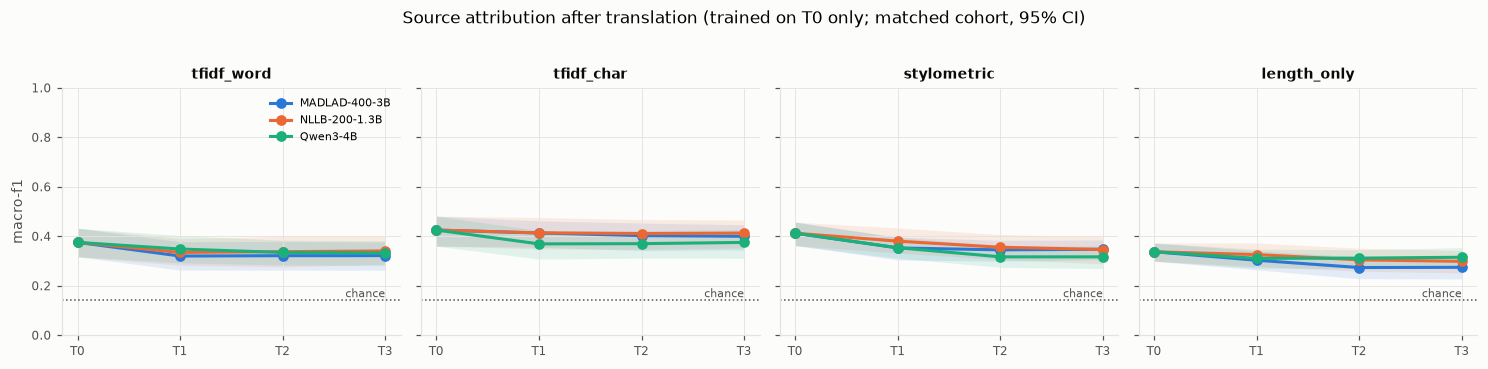

In [5]:
def curve_plot(s, title, fname, metric="macro_f1"):
    fig, axes = plt.subplots(1, len(MODELS), figsize=(3.4 * len(MODELS), 3.2), sharey=True)
    for ax, mname in zip(axes, MODELS):
        g = s[s.model == mname]
        t0v = g[g.translator == "original"].iloc[0]
        for t in TR:
            h = g[g.translator == t].sort_values("stage")
            x = [0] + h.stage.str[1].astype(int).tolist()
            y = [t0v[metric]] + h[metric].tolist()
            lo = [t0v[metric + "_ci_low"]] + h[metric + "_ci_low"].tolist()
            hi = [t0v[metric + "_ci_high"]] + h[metric + "_ci_high"].tolist()
            ax.plot(x, y, marker="o", color=COL[t], label=NAMES[t])
            ax.fill_between(x, lo, hi, color=COL[t], alpha=0.12, linewidth=0)
        ax.axhline(CHANCE, color=plots.INK2, ls=":", lw=1)
        ax.text(3, CHANCE, " chance", va="bottom", ha="right", fontsize=7, color=plots.INK2)
        ax.set_xticks(range(4), ["T0", "T1", "T2", "T3"])
        ax.set_title(mname, fontsize=9)
        ax.set_ylim(0, 1)
    axes[0].set_ylabel(metric.replace("_", "-"))
    axes[0].legend(fontsize=7, loc="upper right")
    fig.suptitle(title, y=1.03, fontsize=11)
    fig.tight_layout()
    plots.save(fig, fname)
    plt.show()
curve_plot(sc, "Source attribution after translation (trained on T0 only; matched cohort, 95% CI)", "rq2_macro_f1_by_round")

## 3. Per-class results and confusion matrices

best model on original T0: tfidf_char


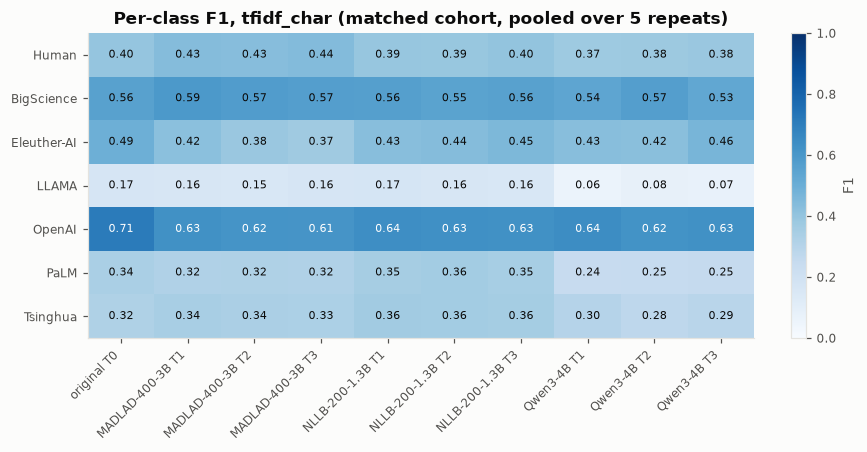

,precision,recall,f1,support_per_repeat
class,,,,
Human,0.349,0.455,0.395,29
BigScience,0.489,0.643,0.556,28
Eleuther-AI,0.496,0.492,0.494,26
LLAMA,0.181,0.156,0.167,27
OpenAI,0.742,0.679,0.709,28
PaLM,0.442,0.271,0.336,28
Tsinghua,0.323,0.319,0.321,27


In [6]:
best = sc[sc.translator == "original"].sort_values("macro_f1", ascending=False).model.iloc[0]
print("best model on original T0:", best)
pc = classify.per_class(preds[preds.matched], BY, LABELS)
pc.to_csv(OUT / "per_class.csv", index=False)
b = pc[pc.model == best].copy()
b["set"] = b.translator.map(lambda x: NAMES.get(x, "original")) + " " + b.stage
heat = b.pivot_table(index="class", columns="set", values="f1").reindex(LABELS)
heat = heat[["original T0"] + [f"{NAMES[t]} T{k}" for t in TR for k in (1, 2, 3)]]
fig, ax = plt.subplots(figsize=(1.0 + 0.75 * heat.shape[1], 3.6))
im = ax.imshow(heat.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=45, ha="right")
ax.set_yticks(range(len(LABELS)), LABELS)
ax.grid(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.6 else plots.INK)
fig.colorbar(im, ax=ax, fraction=0.03, label="F1")
ax.set_title(f"Per-class F1, {best} (matched cohort, pooled over {NR} repeats)")
plots.save(fig, "rq2_per_class_f1")
plt.show()
display(b[b.translator == "original"][["class", "precision", "recall", "f1", "support_per_repeat"]].set_index("class"))

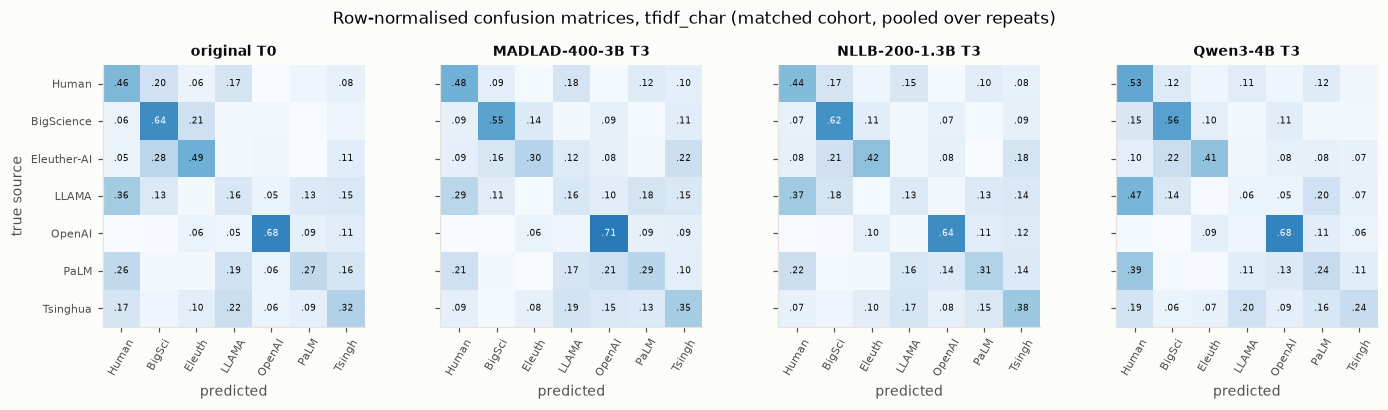

In [7]:
sets = [("original", "T0")] + [(t, "T3") for t in TR]
fig, axes = plt.subplots(1, len(sets), figsize=(3.3 * len(sets), 3.4))
conf_rows = []
for ax, (t, s) in zip(axes, sets):
    part = preds[preds.matched & (preds.model == best) & (preds.translator == t) & (preds.stage == s)]
    cm = classify.confusion(part, LABELS)
    raw = classify.confusion(part, LABELS, normalize=False)
    conf_rows.append(raw.stack().rename("count").reset_index().assign(model=best, translator=t, stage=s))
    ax.imshow(cm.to_numpy(), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(LABELS)), [l[:6] for l in LABELS], rotation=60, fontsize=7)
    ax.set_yticks(range(len(LABELS)), LABELS if ax is axes[0] else [""] * len(LABELS), fontsize=7)
    ax.grid(False)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            v = cm.iat[i, j]
            if v >= 0.05:
                ax.text(j, i, f"{v:.2f}".lstrip("0"), ha="center", va="center", fontsize=6,
                        color="white" if v > 0.6 else plots.INK)
    ax.set_title(f"{NAMES.get(t, 'original')} {s}", fontsize=9)
    ax.set_xlabel("predicted")
axes[0].set_ylabel("true source")
fig.suptitle(f"Row-normalised confusion matrices, {best} (matched cohort, pooled over repeats)", y=1.02, fontsize=11)
fig.tight_layout()
plots.save(fig, "rq2_confusion_T0_T3")
plt.show()
for t in TR:
    for s in ("T1", "T2"):
        part = preds[preds.matched & (preds.model == best) & (preds.translator == t) & (preds.stage == s)]
        conf_rows.append(classify.confusion(part, LABELS, normalize=False).stack().rename("count").reset_index()
                         .assign(model=best, translator=t, stage=s))
pd.concat(conf_rows).to_csv(OUT / "confusion_counts.csv", index=False)

## 4. Ablation: shared opening removed

The measured shared opening (section 1) is removed from **every** text: training T0 texts and all test texts, for
every source including Human. The full experiment is then repeated. Stylometric features are recomputed on the
stripped texts with the same cached spaCy pipeline. Original texts are not modified.

words removed per text: mean 21.6 | texts left empty: 8


macro_f1_ablated                                   macro_f1_full                                  
model                    length_only stylometric tfidf_char tfidf_word   length_only stylometric tfidf_char tfidf_word
translator    stage                                                                                                   
MADLAD-400-3B T1               0.337       0.364      0.399      0.385         0.303       0.352      0.413      0.320
              T2               0.317       0.328      0.392      0.389         0.273       0.345      0.402      0.321
              T3               0.311       0.333      0.390      0.386         0.274       0.347      0.399      0.321
NLLB-200-1.3B T1               0.335       0.405      0.445      0.404         0.325       0.380      0.413      0.334
              T2               0.313       0.377      0.422      0.399         0.304       0.355      0.410      0.337
              T3               0.310       0.359      0.419      0.404         0.298       0.346      0.412      0.340
Qwen3-4B      T1               0.310       0.333      0.379      0.382         0.310       0.353      0.369      0.348
              T2               0.311       0.299      0.372      0.369         0.311       0.316      0.370      0.334
              T3               0.327       0.306      0.377      0.362         0.315       0.316      0.375      0.332
original      T0               0.338       0.420      0.465      0.451         0.337       0.412      0.425      0.375

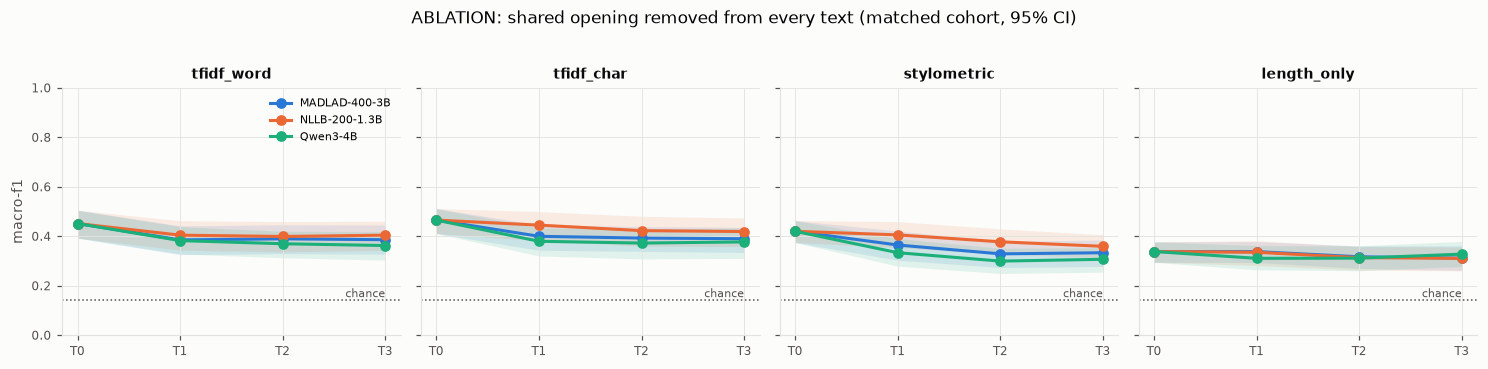

In [8]:
strip = classify.strip_opening(en[["text_id", "item_id", "article_id", "source_label", "translator", "stage", "text"]],
                               en.opening_words)
strip["text_sha256"] = strip.text.map(corpus.sha256_text)
refl = json.loads((paths.results("shared_features") / "reference_lists.json").read_text())
sf = features.compute(strip, refl, n_process=1, log=lambda m: None)
strip = strip.merge(sf[["text_sha256", "n_words", "n_sentences"] + STYLE], on="text_sha256", how="left")
strip = classify.add_length_cols(strip)
print("words removed per text: mean", round(en.opening_words.mean(), 1), "| texts left empty:", int((strip.text.str.len() == 0).sum()))
EVAL_S = {k: strip[strip.text_id.isin(v.text_id)] for k, v in EVAL.items()}
preds_s = run_all(strip[strip.stage == "T0"], EVAL_S, "opening_removed")
preds_s["matched"] = preds_s.item_id.isin(D["matched_items"])
sc_s = classify.scores(preds_s[preds_s.matched], BY, LABELS, n_boot=1000, seed=SEED).assign(cohort="matched")
sc_s.to_csv(OUT / "scores_opening_removed.csv", index=False)
cmp_ = sc.merge(sc_s, on=BY, suffixes=("_full", "_ablated"))
cmp_["delta_macro_f1"] = cmp_.macro_f1_ablated - cmp_.macro_f1_full
cmp_["translator"] = cmp_.translator.map(lambda x: NAMES.get(x, "original"))
display(cmp_.pivot_table(index=["translator", "stage"], columns="model",
                         values=["macro_f1_full", "macro_f1_ablated"]).round(3))
curve_plot(sc_s, "ABLATION: shared opening removed from every text (matched cohort, 95% CI)", "rq2_macro_f1_opening_removed")
pd.concat([preds, preds_s]).to_parquet(OUT / "predictions.parquet", index=False)

## 5. Key results

In [9]:
def get(s, m, t, st):
    r = s[(s.model == m) & (s.translator == t) & (s.stage == st)].iloc[0]
    return f"{r.macro_f1:.3f} [{r.macro_f1_ci_low:.3f}, {r.macro_f1_ci_high:.3f}]"
lines = [f"- Best model on original T0 (**{best}**): macro-F1 {get(sc, best, 'original', 'T0')} (chance {CHANCE:.3f})."]
for t in TR:
    lines.append(f"- {NAMES[t]}: T1 {get(sc, best, t, 'T1')}, T3 {get(sc, best, t, 'T3')}; "
                 f"opening removed T3 {get(sc_s, best, t, 'T3')}.")
lines.append(f"- Length-only control on T0: {get(sc, 'length_only', 'original', 'T0')}.")
display(Markdown("\n".join(lines)))
json.dump({"labels": LABELS, "models": MODELS, "best_model": best, "seed": SEED, "folds": CFG["cv_folds"],
           "repeats": NR, "train": "T0 of training articles", "translators": TR, "chance": CHANCE,
           "hyperparameters": "fixed; see src/sot_research/classify.py make_model"},
          open(OUT / "config.json", "w"), indent=1)

- Best model on original T0 (**tfidf_char**): macro-F1 0.425 [0.360, 0.481] (chance 0.143).
- MADLAD-400-3B: T1 0.413 [0.355, 0.462], T3 0.399 [0.344, 0.446]; opening removed T3 0.390 [0.334, 0.435].
- NLLB-200-1.3B: T1 0.413 [0.348, 0.475], T3 0.412 [0.353, 0.465]; opening removed T3 0.419 [0.358, 0.473].
- Qwen3-4B: T1 0.369 [0.308, 0.423], T3 0.375 [0.311, 0.427]; opening removed T3 0.377 [0.310, 0.433].
- Length-only control on T0: 0.337 [0.299, 0.372].

## Interpretation

Scores are macro-F1 on the matched cohort (193 documents per evaluation set, 31 articles, 5×5 grouped CV).

**1. Source attribution on originals is moderate, and partly a length effect.**
- The best model (character 2-5-gram TF-IDF) reaches macro-F1 0.43 on held-out original texts, three times chance
  (0.14).
- A length-only control already reaches 0.34. Sources differ strongly in length (median 108 words for OpenAI vs 360
  for Human), so a substantial part of "attribution" is length.
- **Distinctiveness by source:**
  - OpenAI (short, formulaic) and BigScience are the most recognisable (F1 0.71 and 0.56).
  - LLAMA and PaLM are often confused with Human: their continuations are long and news-like.

**2. Translation erodes the source signal only slightly, and only in the first round.**
- After one round trip the character model keeps most of its performance: T1 macro-F1 is 0.41 (MADLAD), 0.41
  (NLLB) and 0.37 (Qwen).
- Rounds 2 and 3 change almost nothing (T3: 0.40, 0.41, 0.38).
- The word and stylometric models lose more (0.41 → 0.32-0.35 stylometric at T3), but all stay well above chance.
- This mirrors RQ1: most change happens in round 1, and the chains then converge.

**3. Translators differ in how much source signal survives.**
- Qwen, which paraphrases most (RQ1), removes the most attribution signal from character n-grams (0.375 at T3 vs
  about 0.40-0.41).
- Sentence-level MT systems preserve more of the original surface form, and with it more of the source signal.
- The differences between translators are smaller than the bootstrap CIs (±0.05-0.06), so they are suggestive, not
  conclusive.

**4. The shared opening is not what the classifier uses.**
- Removing the measured shared opening from every text (21.6 words on average) does **not** reduce performance. T0
  character macro-F1 is 0.47 without it vs 0.43 with it, and the translated sets behave similarly.
- The opening is identical across sources, so it carries no source information and only dilutes the signal.
- In translations, the measured opening shortens for MADLAD and Qwen (median about 10-24 words), because they render
  the same opening differently in each text. NLLB keeps it identical (about 30 words).

## Limitations
- **Small test sets:** only 31 articles (about 6 per test fold) and about 28 documents per class. Confidence
  intervals are wide (±0.05-0.06), and translator differences are not individually significant.
- **Fixed models:** hyperparameters are fixed and untuned, so better tuned or neural classifiers could score higher.
  This experiment measures *relative* survival of the signal, not maximal attainable attribution.
- **Length confound:** length is a strong confound. Both the length-only control and the stylometric model use
  length-normalised rates, but text length itself survives translation almost unchanged (RQ1 length ratios
  0.92-1.0).
- **Opening ablation:** the shared-opening ablation removes a measured verbatim prefix. In LLM-translated texts,
  paraphrased remnants of the opening may remain.
- **Training data:** training uses original texts only, by design. Training on translated texts of training
  articles would answer a different question (attribution robust to translation).